# ¿Se puede separar el dulce de leche repostero? (prueba)
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026**

El segundo nivel del tag **DDL** que había cuando se hizo esta prueba (mezcla de gaussianas sobre humedad, grasa, proteínas y cenizas reescaladas dentro
del tag, k = 6 por BIC; `src/mejoras_clustering.py`, `subtags`) deja dos subtags: **DDL_FAMILIAR** y **DDL_HELADERO**.
El resto queda como «DDL». La pregunta es si el **repostero** puede tener su propio subtag.

**Nota (después de las pruebas por familia):** el notebook único reemplazó esta mezcla por el segundo nivel de `src/segundo_nivel.py` (en el DDL, la regresión logística de `prueba_subtipo_ddl.ipynb`, que sí da DDL_REPOSTERO). Esta prueba recalcula la mezcla (es determinista) y compara contra ella, como cuando se hizo.


Este cuaderno es **de prueba** y no cambia nada del notebook completo. Pasos:

| | qué se mira |
|---|---|
| 1 | conteos y distribución de cada análisis por subtipo dentro del DDL: ¿dónde queda el repostero? |
| 2 | **diagnóstico supervisado** (LDA y regresión logística con validación cruzada estratificada). No es el modelo: si ni un supervisado lo separa, ningún agrupamiento lo va a separar |
| 3 | en qué componentes de la mezcla actual cae el repostero; la mezcla con k de 1 a 12 (y más) y covarianza full / diag |
| 4 | una regla simple que lo aísle, con su pureza y cobertura |
| 5 | causa probable: análisis fuera de la composición centesimal, texto de las descripciones y separabilidad por cliente (IND-nn) |

El subtipo de referencia es `desc_subtipo` de Senasa; si falta, el de `desc_producto` y, si no, el de
`mq_tipo_muestra.csv` (`mejoras_clustering.subtipo_referencia`). **Pureza** = % de repostero entre las muestras elegidas
que tienen subtipo conocido. **Cobertura** = % de los reposteros conocidos que quedan elegidos. Semilla 42. Al final,
el **veredicto**.

## 0 · Rutas, parámetros y funciones

In [1]:
import sys
import warnings
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

import rutas as R
import mejoras_clustering as M
from datos_clase41 import COLUMNAS, SEMILLA, a_numero, leer_mq, leer_senasa

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

SALIDA = R.RESULTADOS / "prueba_ddl_repostero"; SALIDA.mkdir(parents=True, exist_ok=True)
SUBTIPOS = ["FAMILIAR", "REPOSTERO", "HELADERO", "sin subtipo"]
COLOR = {"FAMILIAR": "#2a78d6", "REPOSTERO": "#eb6834", "HELADERO": "#1baf7a", "sin subtipo": "#b0aea5"}
TINTA, TINTA2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "font.size": 9})
EJEMPLOS = {"MQ-34408-01": "repostero", "MQ-35246-01": "familiar", "MQ-34696-01": "heladero"}
REGLA = dict(humedad_max=27.6, cenizas_max=2.0)       # la regla simple de la sección 4 (umbrales redondeados)
KS = range(1, 13)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
CV_REP = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEMILLA)
MODELOS = {"LDA": lambda: make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
           "regresión logística": lambda: make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))}
OTROS = {"aw": "Resultado Actividad de agua (% Aw) (*)", "carbohidratos": "Resultado Carbohidratos Totales g/ 100g (*)",
         "lactosa": "Resultado Lactosa g /100g (*)", "sodio": "Resultado Sodio mg /100g (*)"}
S = leer_senasa()
MQ_CRUDO, _ = leer_mq()
MQ_CRUDO = MQ_CRUDO.set_index("codigo")
RES = {}


def cargar_ddl(v, con_mq):
    # Muestras del tag DDL tal como quedaron en clusters_{v}.csv (con los outliers, que también llevan tag) + subtipo,
    # cliente (IND-nn), otros análisis de Senasa y de MQ. Recalcula el subtag de la mezcla (el segundo nivel anterior).
    muestras, _ = M.preparar(con_mq, S)
    cl = pd.read_csv(R.TABLAS / f"clusters_{v}.csv", encoding="utf-8-sig")
    d = cl[cl["tag"] == "DDL"].merge(muestras[["Identificador", "subtipo_ref", "fuente_subtipo"]], on="Identificador",
                                    how="left", validate="one_to_one").reset_index(drop=True)
    cr = S.crudo.set_index("Identificador")
    d["cliente"] = d["Identificador"].map(cr["Cliente"])
    for k, col in OTROS.items():
        d[k] = a_numero(d["Identificador"].map(cr[col]))
    for k in ["cloruro_nacl_g100g", "cloruro_mg100g", "solidos", "caseina", "ceniza_acida", "grasa_libre"]:
        d[f"mq_{k}"] = d["Identificador"].map(MQ_CRUDO[k])
    d["subtipo"] = d["subtipo_ref"].fillna("sin subtipo")
    X = d[COLUMNAS].to_numpy()
    sub, modelos = M.subtags(X, np.array(["DDL"] * len(d), dtype=object), d["subtipo_ref"])
    # El notebook único ya no usa esta mezcla (su segundo nivel sale de segundo_nivel.py, con la logística que salió de
    # prueba_subtipo_ddl). Acá se recalcula la mezcla, que es determinista, y su subtag reemplaza al de clusters_*.csv:
    # la prueba compara contra el segundo nivel que había cuando se hizo.
    d["subtag"] = sub
    m = modelos["DDL"]
    d["componente"] = m["gmm"].predict(m["escalador"].transform(X))
    return d, m


def pureza_cobertura(elegidas, subtipo, objetivo="REPOSTERO"):
    elegidas = np.asarray(elegidas, dtype=bool); s = pd.Series(np.asarray(subtipo, dtype=object))
    conocido = s != "sin subtipo"
    n_c = int((elegidas & conocido).sum()); n_o = int((elegidas & (s == objetivo)).sum())
    return {"elegidas": int(elegidas.sum()), "con subtipo": n_c, "sin subtipo": int((elegidas & ~conocido).sum()),
            f"{objetivo.lower()}s": n_o, "% pureza": round(100 * n_o / n_c, 1) if n_c else np.nan,
            "% cobertura": round(100 * n_o / (s == objetivo).sum(), 1)}


def supervisado(d, positivo, negativos):
    s = d[d["subtipo"].isin([positivo] + negativos)]
    y = (s["subtipo"] == positivo).astype(int).to_numpy(); Xs = s[COLUMNAS].to_numpy()
    filas, coefs, matrices = [], {}, {}
    for nombre, f in MODELOS.items():
        pred = cross_val_predict(f(), Xs, y, cv=CV)
        rep = cross_val_score(f(), Xs, y, cv=CV_REP, scoring="balanced_accuracy")
        filas.append({"modelo": nombre, "n": len(y), f"n {positivo.lower()}": int(y.sum()),
                      "exactitud balanceada (5 pliegues)": round(balanced_accuracy_score(y, pred), 3),
                      "media 5×10": round(rep.mean(), 3), "desvío 5×10": round(rep.std(), 3)})
        matrices[nombre] = pd.DataFrame(confusion_matrix(y, pred), index=[f"real: otro", f"real: {positivo}"],
                                        columns=[f"predicho: otro", f"predicho: {positivo}"])
        ajuste = f().fit(Xs, y)[-1]
        coefs[nombre] = (ajuste.scalings_[:, 0] if nombre == "LDA" else ajuste.coef_[0])
    return pd.DataFrame(filas).set_index("modelo"), matrices, pd.DataFrame(coefs, index=COLUMNAS).round(2)


def guardar(fig, nombre):
    fig.savefig(SALIDA / nombre, dpi=150, bbox_inches="tight", facecolor="white")
    print("PNG:", (SALIDA / nombre).relative_to(R.RAIZ))

## 1 · Solo Senasa
### 1.1 · Conteos por subtipo dentro del DDL
Las muestras con tag DDL de `resultados/tablas/clusters_senasa.csv` (incluidos los outliers, que también llevan tag). El
subtag es el de la mezcla, recalculada con `M.subtags` (el segundo nivel anterior; el de `clusters_senasa.csv` ya es otro).

In [2]:
v = "senasa"
d, modelo = cargar_ddl(v, False)
print(f"{len(d)} muestras con tag DDL · mezcla con k = {modelo['k_bic']} · subtag de la mezcla recalculado")
display(pd.crosstab(d["subtipo"], d["subtag"], margins=True, margins_name="total").reindex(SUBTIPOS + ["total"]))
print("Fuente del subtipo:"); display(pd.crosstab(d["subtipo"], d["fuente_subtipo"].fillna("-")))

2116 muestras con tag DDL · mezcla con k = 6 · subtag de la mezcla recalculado


subtag,DDL,DDL_FAMILIAR,DDL_HELADERO,total
subtipo,,,,
FAMILIAR,165,584,0,749
REPOSTERO,552,68,0,620
HELADERO,31,0,121,152
sin subtipo,416,179,0,595
total,1164,831,121,2116


Fuente del subtipo:


fuente_subtipo,-,Senasa,Senasa (desc_producto),mq_tipo_muestra
subtipo,,,,
FAMILIAR,0,749,0,0
HELADERO,0,152,0,0
REPOSTERO,0,612,6,2
sin subtipo,595,0,0,0


### 1.2 · Distribución por subtipo
Medianas y percentiles 10 y 90 de los cuatro análisis. Abajo, los violines (con la mediana marcada) y la actividad de
agua (Aw), que es el único análisis extra con suficientes muestras de DDL. Los cloruros, la caseína, la ceniza ácida y la
grasa libre de MQ **no tienen ningún valor** en las muestras de DDL; los sólidos de MQ son 100 − humedad y no agregan nada.

humedad                       grasa                   proteinas                   cenizas                  
              count    10%    50%    90%  count   10%   50%   90%     count   10%   50%   90%   count   10%   50%   90%
subtipo                                                                                                                
FAMILIAR      749.0  27.47  28.70  29.87  749.0  6.15  6.75  7.60     749.0  5.36  5.84  6.58   749.0  1.19  1.36  1.56
REPOSTERO     620.0  24.53  26.64  28.25  620.0  6.00  6.84  8.36     620.0  5.18  6.63  7.73   620.0  1.16  1.50  1.76
HELADERO      152.0  20.66  21.76  25.49  152.0  5.36  7.02  7.37     152.0  6.16  6.73  7.23   152.0  2.03  2.56  2.77
sin subtipo   595.0  27.26  28.81  30.58  595.0  6.17  7.21  8.93     595.0  5.70  7.16  8.61   595.0  1.28  1.70  2.01

Otros análisis de Senasa (n con valor y mediana):


aw        carbohidratos        lactosa        sodio        
            count median         count median   count median count  median
subtipo                                                                   
FAMILIAR       89  0.836            17  55.95      17   6.11    13  155.10
REPOSTERO     220  0.804            25  60.12      21   4.94    11  163.65
HELADERO        2  0.722             6  60.32       1   9.14     5  383.60
sin subtipo    10  0.840            79  51.15       4   6.88    13  150.10

Análisis de MQ con valor en el DDL: {'mq_cloruro_nacl_g100g': 0, 'mq_cloruro_mg100g': 0, 'mq_solidos': 649, 'mq_caseina': 0, 'mq_ceniza_acida': 0, 'mq_grasa_libre': 0}


,Identificador,subtipo,subtag,componente,humedad,grasa,proteinas,cenizas
1513,MQ-34408-01,REPOSTERO,DDL,5,26.56,7.31,7.33,1.63
1525,MQ-34696-01,HELADERO,DDL_HELADERO,3,21.26,7.33,6.91,2.90
1562,MQ-35246-01,FAMILIAR,DDL_FAMILIAR,4,27.97,6.97,5.69,1.29


PNG: resultados\prueba_ddl_repostero\violines_senasa.png


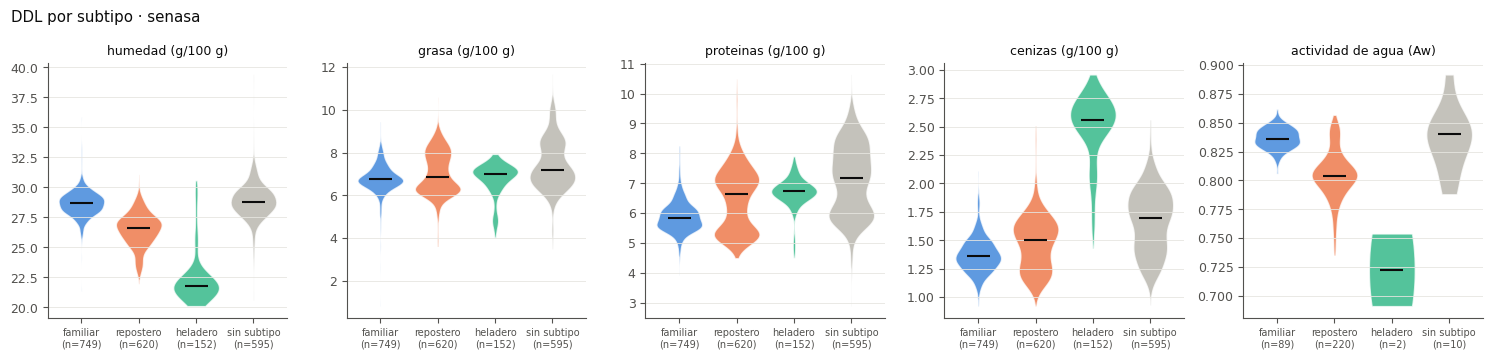

PNG: resultados\prueba_ddl_repostero\dispersion_senasa.png


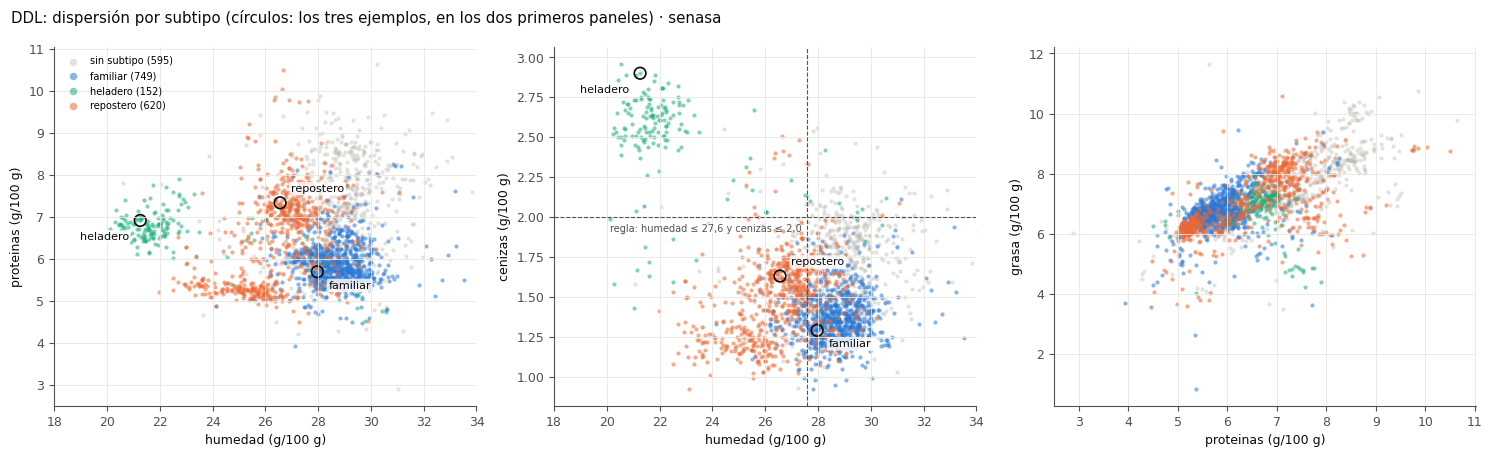

In [3]:
resumen = d.groupby("subtipo")[COLUMNAS].describe(percentiles=[.1, .5, .9]).loc[SUBTIPOS]
display(pd.concat({c_: resumen[c_][["count", "10%", "50%", "90%"]] for c_ in COLUMNAS}, axis=1).round(2))
otros = d.groupby("subtipo")[list(OTROS)].agg(["count", "median"]).reindex(SUBTIPOS).round(3)
print("Otros análisis de Senasa (n con valor y mediana):"); display(otros)
print("Análisis de MQ con valor en el DDL:", {k_: int(d[k_].notna().sum()) for k_ in d.columns if k_.startswith("mq_")})
display(d[d["Identificador"].isin(EJEMPLOS)][["Identificador", "subtipo", "subtag", "componente"] + COLUMNAS])

fig, axs = plt.subplots(1, 5, figsize=(15, 3.6))
for ax, var in zip(axs, COLUMNAS + ["aw"]):
    grupos = [d.loc[d["subtipo"] == s_, var].dropna().to_numpy() for s_ in SUBTIPOS]
    pos = [i for i, g_ in enumerate(grupos) if len(g_) > 1]
    partes = ax.violinplot([grupos[i] for i in pos], positions=pos, showmedians=True, showextrema=False, widths=0.8)
    for cuerpo, i in zip(partes["bodies"], pos):
        cuerpo.set_facecolor(COLOR[SUBTIPOS[i]]); cuerpo.set_edgecolor("white"); cuerpo.set_alpha(0.75)
    partes["cmedians"].set_color(TINTA); partes["cmedians"].set_linewidth(1.5)
    ax.set_xticks(range(len(SUBTIPOS))); ax.set_xticklabels([f"{s_.lower()}\n(n={len(g_)})" for s_, g_ in zip(SUBTIPOS, grupos)], fontsize=7)
    ax.set_title({"aw": "actividad de agua (Aw)"}.get(var, f"{var} (g/100 g)"), fontsize=9, color=TINTA); ax.grid(axis="x", visible=False)
fig.suptitle(f"DDL por subtipo · {v}", x=0.01, ha="left", color=TINTA)
fig.tight_layout(); guardar(fig, f"violines_{v}.png"); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (x_, y_) in zip(axs, [("humedad", "proteinas"), ("humedad", "cenizas"), ("proteinas", "grasa")]):
    for s_ in ["sin subtipo", "FAMILIAR", "HELADERO", "REPOSTERO"]:
        q = d[d["subtipo"] == s_]
        ax.scatter(q[x_], q[y_], s=9, color=COLOR[s_], alpha=0.55 if s_ != "sin subtipo" else 0.35, lw=0, label=f"{s_.lower()} ({len(q)})")
    for cod, rot in EJEMPLOS.items():
        q = d[d["Identificador"] == cod]
        if len(q) and x_ == "humedad":
            ax.scatter(q[x_], q[y_], s=70, facecolors="none", edgecolors=TINTA, lw=1.2)
            ax.annotate(rot, (q[x_].iloc[0], q[y_].iloc[0]), xytext={"repostero": (8, 8), "familiar": (8, -12), "heladero": (-8, -14)}[rot],
                        textcoords="offset points", fontsize=8, color=TINTA, ha="left" if rot != "heladero" else "right",
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
    if x_ == "humedad":
        ax.set_xlim(18, 34)
    ax.set_xlabel(f"{x_} (g/100 g)"); ax.set_ylabel(f"{y_} (g/100 g)")
    if (x_, y_) == ("humedad", "cenizas"):
        ax.axvline(REGLA["humedad_max"], color=TINTA2, lw=0.8, ls="--"); ax.axhline(REGLA["cenizas_max"], color=TINTA2, lw=0.8, ls="--")
        ax.text(REGLA["humedad_max"] - 0.2, REGLA["cenizas_max"] - 0.04, "regla: humedad ≤ 27,6 y cenizas ≤ 2,0", ha="right", va="top", fontsize=7, color=TINTA2)
axs[0].legend(fontsize=7, markerscale=1.8, frameon=False, loc="upper left")
fig.suptitle(f"DDL: dispersión por subtipo (círculos: los tres ejemplos, en los dos primeros paneles) · {v}", x=0.01, ha="left", color=TINTA)
fig.tight_layout(); guardar(fig, f"dispersion_{v}.png"); plt.show()

### 1.3 · Diagnóstico supervisado
LDA y regresión logística (con peso de clase balanceado) sobre las cuatro columnas estandarizadas. Validación cruzada
estratificada de 5 pliegues para la matriz de confusión, y 5 pliegues × 10 repeticiones para la media y el desvío de la
**exactitud balanceada** (0,5 = azar). Tres preguntas: repostero contra familiar, repostero contra el resto (familiar +
heladero) y, como referencia de algo que sí se separa, heladero contra el resto. Los coeficientes están en unidades de
desvío: positivo = empuja hacia el primer subtipo.

In [4]:
sup = {}
for pos_, negs_ in [("REPOSTERO", ["FAMILIAR"]), ("REPOSTERO", ["FAMILIAR", "HELADERO"]), ("HELADERO", ["FAMILIAR", "REPOSTERO"])]:
    nombre = f"{pos_.lower()} contra {' + '.join(n_.lower() for n_ in negs_)}"
    tabla, mats, coefs = supervisado(d, pos_, negs_); sup[nombre] = tabla
    print(nombre); display(tabla)
    for k_, m_ in mats.items():
        print(f"  matriz de confusión ({k_}):"); display(m_)
    print("  coeficientes:"); display(coefs.T)

repostero contra familiar


,n,n repostero,exactitud balanceada (5 pliegues),media 5×10,desvío 5×10
modelo,,,,,
LDA,1369,620,0.871,0.872,0.017
regresión logística,1369,620,0.868,0.868,0.017


  matriz de confusión (LDA):


,predicho: otro,predicho: REPOSTERO
real: otro,671,78
real: REPOSTERO,95,525


  matriz de confusión (regresión logística):


,predicho: otro,predicho: REPOSTERO
real: otro,652,97
real: REPOSTERO,83,537


... (14 outputs left out)

  matriz de confusión (regresión logística):


,predicho: otro,predicho: HELADERO
real: otro,1356,13
real: HELADERO,1,151


  coeficientes:


,humedad,grasa,proteinas,cenizas
LDA,-0.55,-0.06,-1.05,2.51
regresión logística,-2.23,-0.07,-2.10,5.21


### 1.4 · ¿En qué componentes de la mezcla actual cae el repostero?
Componente × subtipo de la mezcla (la que guardaba el joblib antes del segundo nivel por familia). El subtag sale de `proponer_subtag`: un componente lo
lleva si su subtipo mayoritario tiene pureza de al menos 60 % y cobertura de al menos 50 %, con suficientes muestras de
subtipo conocido.

subtipo,FAMILIAR,REPOSTERO,HELADERO,sin subtipo,total
componente,,,,,
0,5,9,0,189,203
1,4,159,0,3,166
2,62,119,31,101,313
3,0,0,121,0,121
4,584,68,0,179,831
5,94,265,0,123,482
total,749,620,152,595,2116


,subtag,muestras,humedad,grasa,proteinas,cenizas,con subtipo,subtipo mayoritario,% pureza,% cobertura
subgrupo,,,,,,,,,,
0,DDL,203,29.31,8.70,8.20,1.90,14,REPOSTERO,64.0,1.0
1,DDL,166,25.23,6.22,5.25,1.20,163,REPOSTERO,98.0,26.0
2,DDL,313,27.58,6.49,6.57,1.67,212,REPOSTERO,56.0,19.0
3,DDL_HELADERO,121,21.66,6.79,6.83,2.62,121,HELADERO,100.0,80.0
4,DDL_FAMILIAR,831,28.52,6.70,5.81,1.34,652,FAMILIAR,90.0,78.0
5,DDL,482,27.77,7.58,7.11,1.63,359,REPOSTERO,74.0,43.0


Componentes con mayoría de repostero: ['0', '1', '2', '5']
Si se fusionan esos componentes en un DDL_REPOSTERO: {'elegidas': 1164, 'con subtipo': 748, 'sin subtipo': 416, 'reposteros': 552, '% pureza': 73.8, '% cobertura': np.float64(89.0)}
PNG: resultados\prueba_ddl_repostero\componentes_senasa.png


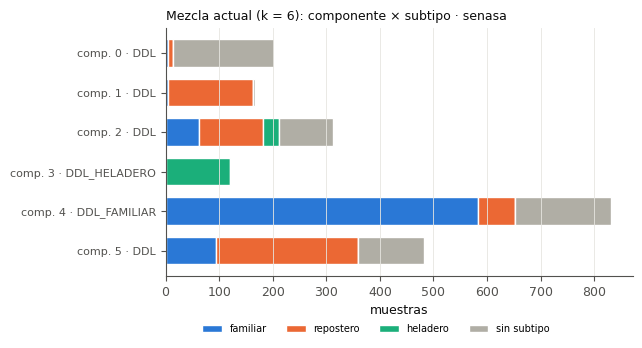

In [5]:
display(pd.crosstab(d["componente"], d["subtipo"], margins=True, margins_name="total")[SUBTIPOS + ["total"]])
display(modelo["descripcion"])
may_rep = [g_ for g_, f_ in modelo["descripcion"].iterrows() if f_["subtipo mayoritario"] == "REPOSTERO"]
print("Componentes con mayoría de repostero:", may_rep)
union_actual = pureza_cobertura(d["componente"].astype(str).isin(may_rep), d["subtipo"])
print("Si se fusionan esos componentes en un DDL_REPOSTERO:", union_actual)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
t_ = pd.crosstab(d["componente"], d["subtipo"])[SUBTIPOS]
izq = np.zeros(len(t_))
for s_ in SUBTIPOS:
    ax.barh(t_.index.astype(str), t_[s_], left=izq, color=COLOR[s_], edgecolor="white", lw=1, label=s_.lower(), height=0.7)
    izq += t_[s_].to_numpy()
sub_ = modelo["descripcion"]["subtag"]
ax.set_yticks(range(len(t_))); ax.set_yticklabels([f"comp. {g_} · {sub_.get(str(g_), '')}" for g_ in t_.index], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("muestras"); ax.grid(axis="y", visible=False)
ax.legend(fontsize=7, frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.45, -0.16))
ax.set_title(f"Mezcla actual (k = {modelo['k_bic']}): componente × subtipo · {v}", loc="left", fontsize=9, color=TINTA)
fig.tight_layout(); guardar(fig, f"componentes_{v}.png"); plt.show()

### 1.5 · La mezcla con un rango de k más amplio (1 a 12) y covarianza full / diag
Misma escala que la actual (dentro del tag) y `n_init = 3`. Para cada k: BIC, el componente con más pureza de repostero
(de al menos 20 muestras) y la **fusión** de todos los componentes con mayoría de repostero entre las de subtipo
conocido. Con covarianza full se siguen probando k hasta 20, para ver si el BIC llega a un mínimo o sigue en meseta.

BIC  mejor comp.: muestras  mejor comp.: % pureza  mejor comp.: % cobertura  fusión: componentes  fusión: % pureza  fusión: % cobertura
covarianza k                                                                                                                                            
full       1   20984                   2116                   40.8                     100.0                    0               NaN                  0.0
           2   17873                   1773                   42.6                      85.0                    0               NaN                  0.0
           3   16951                   1032                   65.1                      64.2                    1              65.1                 64.2
           4   16403                    697                   72.7                      42.9                    2              66.8                 63.4
           5   16847                    296                   82.7                      36.3                    3              70.9                 90.5
           6   15803                    166                   97.5                      25.6                    4              73.8                 89.0
           7   15761                    162                   98.7                      25.3                    5              73.7                 89.8
           8   15747                    164                   97.5                      25.3                    5              74.2                 89.7
           9   15780                    165                   97.5                      25.3                    5              80.4                 83.9
           10  15791                    162                   98.7                      25.3                    6              83.0                 82.7
           11  15794                    159                   98.7                      25.0                    7              79.6                 88.9
           12  15776                    164                   98.1                      25.3                    6              85.8                 78.7
diag       1   24081                   2116                   40.8                     100.0                    0               NaN                  0.0
           2   22414                   1966                   44.1                      98.5                    0               NaN                  0.0
           3   19031                    938                   66.5                      56.5                    1              66.5                 56.5
           4   18481                    229                   77.8                       4.5                    2              67.8                 56.9
           5   17560                    317                   75.8                      35.3                    3              71.4                 91.8
           6   16849                    237                   80.5                       5.3                    4              67.5                 90.6
           7   16627                    313                   87.1                      21.8                    5              69.8                 90.8
           8   16421                    164                   98.8                      25.6                    5              77.0                 85.8
           9   16283                    163                   98.8                      25.5                    5              77.5                 85.3
           10  16204                     49                  100.0                       1.9                    6              80.4                 81.3
           11  16170                     51                  100.0                       2.1                    6              82.0                 81.8
           12  16007                     46                  100.0                       1.9                    6              81.3                 80.8

full: BIC mínimo en k = 8 (de 1–20 probados); k con BIC a menos de 100 del mínimo: [6, 7, 8, 9, 10, 11, 12]
diag: BIC mínimo en k = 12 (de 1–12 probados); k con BIC a menos de 100 del mínimo: [12]
PNG: resultados\prueba_ddl_repostero\bic_senasa.png


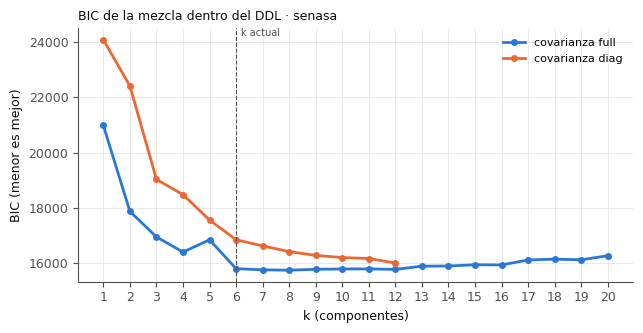

In [6]:
Z = modelo["escalador"].transform(d[COLUMNAS].to_numpy())
filas, bic = [], {}
for cov in ["full", "diag"]:
    for k_ in (range(1, 21) if cov == "full" else KS):
        g_ = GaussianMixture(n_components=k_, covariance_type=cov, n_init=3, random_state=SEMILLA).fit(Z)
        bic[(cov, k_)] = g_.bic(Z)
        if k_ not in KS:
            continue
        e_ = g_.predict(Z); t_ = pd.crosstab(e_, d["subtipo"]).reindex(columns=SUBTIPOS, fill_value=0)
        conoc = t_[["FAMILIAR", "REPOSTERO", "HELADERO"]].sum(axis=1)
        pur = (t_["REPOSTERO"] / conoc.replace(0, np.nan)).where(t_.sum(axis=1) >= 20)
        mejor = pur.idxmax() if pur.notna().any() else None
        mayoria = [i for i in t_.index if conoc[i] > 0 and t_.loc[i, "REPOSTERO"] == t_.loc[i, ["FAMILIAR", "REPOSTERO", "HELADERO"]].max()]
        u_ = pureza_cobertura(np.isin(e_, mayoria), d["subtipo"])
        filas.append({"covarianza": cov, "k": k_, "BIC": round(bic[(cov, k_)]),
                      "mejor comp.: muestras": int(t_.loc[mejor].sum()) if mejor is not None else 0,
                      "mejor comp.: % pureza": round(100 * pur[mejor], 1) if mejor is not None else np.nan,
                      "mejor comp.: % cobertura": round(100 * t_.loc[mejor, "REPOSTERO"] / t_["REPOSTERO"].sum(), 1) if mejor is not None else np.nan,
                      "fusión: componentes": len(mayoria), "fusión: % pureza": u_["% pureza"], "fusión: % cobertura": u_["% cobertura"]})
barrido = pd.DataFrame(filas).set_index(["covarianza", "k"]); display(barrido)
for cov in ["full", "diag"]:
    b_ = {k_: bic[(cov, k_)] for (c_, k_) in bic if c_ == cov}
    kmin = min(b_, key=b_.get)
    print(f"{cov}: BIC mínimo en k = {kmin} (de {min(b_)}–{max(b_)} probados); "
          f"k con BIC a menos de 100 del mínimo: {[k_ for k_ in b_ if b_[k_] - b_[kmin] < 100]}")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for cov, col_ in [("full", "#2a78d6"), ("diag", "#eb6834")]:
    ks_ = sorted(k_ for (c_, k_) in bic if c_ == cov)
    ax.plot(ks_, [bic[(cov, k_)] for k_ in ks_], marker="o", ms=4, lw=2, color=col_, label=f"covarianza {cov}")
ax.axvline(modelo["k_bic"], color=TINTA2, lw=0.8, ls="--"); ax.text(modelo["k_bic"] + 0.2, ax.get_ylim()[1], "k actual", va="top", fontsize=7, color=TINTA2)
ax.set_xlabel("k (componentes)"); ax.set_ylabel("BIC (menor es mejor)"); ax.legend(frameon=False, fontsize=8)
ax.set_xticks(range(1, 21))
ax.set_title(f"BIC de la mezcla dentro del DDL · {v}", loc="left", fontsize=9, color=TINTA)
fig.tight_layout(); guardar(fig, f"bic_{v}.png"); plt.show()

### 1.6 · Una regla simple
Un árbol de decisión de profundidad 1 a 3 (peso de clase balanceado, hojas de al menos 30 muestras), entrenado solo con
las muestras de subtipo conocido, propone los cortes; su exactitud balanceada se mide con validación cruzada. Después se
evalúa la regla fija redondeada **humedad ≤ {REGLA['humedad_max']} y cenizas ≤ {REGLA['cenizas_max']}** (la misma en
las dos versiones) sobre todo el DDL, y la regla aplicada después del heladero (solo a lo que la mezcla no manda a
DDL_HELADERO).

In [7]:
con = d[d["subtipo"] != "sin subtipo"]; y_ = (con["subtipo"] == "REPOSTERO").astype(int)
for prof in [1, 2, 3]:
    arbol = lambda: DecisionTreeClassifier(max_depth=prof, min_samples_leaf=30, class_weight="balanced", random_state=SEMILLA)
    ba = cross_val_score(arbol(), con[COLUMNAS], y_, cv=CV_REP, scoring="balanced_accuracy")
    print(f"árbol de profundidad {prof}: exactitud balanceada {ba.mean():.3f} ± {ba.std():.3f}")
    if prof == 2:
        print(export_text(arbol().fit(con[COLUMNAS], y_), feature_names=COLUMNAS, decimals=2))
regla = (d["humedad"] <= REGLA["humedad_max"]) & (d["cenizas"] <= REGLA["cenizas_max"])
reglas = {"regla: humedad ≤ 27,6 y cenizas ≤ 2,0": regla,
          "regla, fuera de DDL_HELADERO": regla & (d["subtag"] != "DDL_HELADERO"),
          "regla + (humedad ≤ 29 y proteínas > 6,8)": regla | ((d["humedad"] <= 29) & (d["proteinas"] > 6.8) & (d["cenizas"] <= REGLA["cenizas_max"])),
          "fusión de componentes de la mezcla actual": d["componente"].astype(str).isin(may_rep)}
t_reglas = pd.DataFrame({n_: pureza_cobertura(r_, d["subtipo"]) for n_, r_ in reglas.items()}).T
display(t_reglas)
print("Qué subtipo queda adentro de la regla:"); display(pd.crosstab(regla.map({True: "dentro", False: "fuera"}), d["subtipo"])[SUBTIPOS])

# esquema completo propuesto: DDL_HELADERO de la mezcla; después la regla → DDL_REPOSTERO; después DDL_FAMILIAR de la mezcla
propuesto = np.where(d["subtag"] == "DDL_HELADERO", "DDL_HELADERO", np.where(regla, "DDL_REPOSTERO", d["subtag"]))
print("Esquema propuesto (heladero → regla de repostero → familiar) contra el subtipo:")
display(pd.crosstab(pd.Series(propuesto, name="subtag propuesto"), d["subtipo"], margins=True, margins_name="total")[SUBTIPOS + ["total"]])
esquema = pd.DataFrame({st_: pureza_cobertura(propuesto == f"DDL_{st_}", d["subtipo"], st_) for st_ in ["FAMILIAR", "REPOSTERO", "HELADERO"]}).T
esquema = esquema[["elegidas", "con subtipo", "sin subtipo", "% pureza", "% cobertura"]]
print("Pureza y cobertura de cada subtag con el esquema propuesto (antes: familiar 90 / 78, heladero 100 / 80):"); display(esquema)
anio = pd.to_datetime(d["Identificador"].map(S.crudo.set_index("Identificador")["Fecha de Recepción"]), errors="coerce", dayfirst=True).dt.year
print("La regla por año de recepción (pureza / cobertura del repostero):")
display(pd.DataFrame({int(a_): pureza_cobertura(regla[anio == a_], d.loc[anio == a_, "subtipo"].reset_index(drop=True))
                      for a_ in sorted(anio.dropna().unique())}).T[["con subtipo", "% pureza", "% cobertura"]])
RES[v] = dict(n=len(d), esquema=esquema, conteos=d["subtipo"].value_counts().to_dict(), medianas=d.groupby("subtipo")[COLUMNAS].median().round(2),
              sup=sup, regla=t_reglas, barrido=barrido, union_actual=union_actual, d=d)

árbol de profundidad 1: exactitud balanceada 0.770 ± 0.021
árbol de profundidad 2: exactitud balanceada 0.860 ± 0.021
|--- humedad <= 27.64
|   |--- humedad <= 22.90
|   |   |--- class: 0
|   |--- humedad >  22.90
|   |   |--- class: 1
|--- humedad >  27.64
|   |--- proteinas <= 6.78
|   |   |--- class: 0
|   |--- proteinas >  6.78
|   |   |--- class: 1



árbol de profundidad 3: exactitud balanceada 0.858 ± 0.023


,elegidas,con subtipo,sin subtipo,reposteros,% pureza,% cobertura
"regla: humedad ≤ 27,6 y cenizas ≤ 2,0",670.0,592.0,78.0,489.0,82.6,78.9
"regla, fuera de DDL_HELADERO",670.0,592.0,78.0,489.0,82.6,78.9
"regla + (humedad ≤ 29 y proteínas > 6,8)",839.0,666.0,173.0,545.0,81.8,87.9
fusión de componentes de la mezcla actual,1164.0,748.0,416.0,552.0,73.8,89.0


Qué subtipo queda adentro de la regla:


subtipo,FAMILIAR,REPOSTERO,HELADERO,sin subtipo
row_0,,,,
dentro,93,489,10,78
fuera,656,131,142,517


Esquema propuesto (heladero → regla de repostero → familiar) contra el subtipo:


subtipo,FAMILIAR,REPOSTERO,HELADERO,sin subtipo,total
subtag propuesto,,,,,
DDL,139,94,21,369,623
DDL_FAMILIAR,517,37,0,148,702
DDL_HELADERO,0,0,121,0,121
DDL_REPOSTERO,93,489,10,78,670
total,749,620,152,595,2116


Pureza y cobertura de cada subtag con el esquema propuesto (antes: familiar 90 / 78, heladero 100 / 80):


,elegidas,con subtipo,sin subtipo,% pureza,% cobertura
FAMILIAR,702.0,554.0,148.0,93.3,69.0
REPOSTERO,670.0,592.0,78.0,82.6,78.9
HELADERO,121.0,121.0,0.0,100.0,79.6


La regla por año de recepción (pureza / cobertura del repostero):


,con subtipo,% pureza,% cobertura
2020,40.0,57.5,52.3
2021,38.0,73.7,49.1
2022,75.0,74.7,78.9
2023,131.0,90.1,90.1
2024,107.0,76.6,91.1
2025,113.0,86.7,79.0
2026,88.0,95.5,81.6


### 1.7 · Causa probable: ¿otra cosa que no sea la composición, o la etiqueta?
Tres miradas. (a) La **actividad de agua** y los carbohidratos, que no entran en el agrupamiento. (b) El **texto** de
`Descripción`, `desc_producto` y `desc_atributos`: ¿se menciona algún espesante o ingrediente (almidón, agar, gelificante,
carragenina, pectina)? ¿`desc_consistencia` dice algo? (c) La separabilidad **por cliente** (solo el código IND-nn):
regresión logística repostero contra familiar dentro de cada cliente con al menos 15 de cada uno, y las medianas.

subtipo,FAMILIAR,REPOSTERO,HELADERO,sin subtipo
almidón,0,0,0,0
agar,0,0,0,0
espesante,0,0,0,0
gelificante,0,0,0,0
carragenina,0,0,0,0
pectina,0,0,0,0
horneable,0,0,0,0
alfajorero,0,27,0,0
balde / cuñete,0,12,1,0


desc_consistencia con valor en el DDL: 0
Repostero dentro de la regla, por cliente, y separabilidad repostero / familiar:


,reposteros,familiares,heladeros,sin subtipo,humedad mediana repostero,proteinas mediana repostero,humedad mediana familiar,proteinas mediana familiar,% repostero en la regla,exactitud balanceada R/F
cliente,,,,,,,,,,
IND-51,459,567,140,11,26.60,6.91,28.81,5.74,84.0,0.931
IND-11,52,136,0,61,27.78,6.25,27.88,6.08,48.0,0.588
IND-107,29,4,0,12,26.42,5.70,28.36,4.48,79.0,NaN
IND-71,17,3,0,2,24.11,5.77,32.44,5.49,88.0,NaN
IND-38,13,4,0,326,26.38,9.73,30.88,8.21,15.0,NaN
IND-52,12,15,2,5,26.10,5.68,27.89,5.04,100.0,NaN
IND-67,9,0,0,89,25.35,6.81,NaN,NaN,100.0,NaN
IND-81,6,0,5,0,26.89,8.02,NaN,NaN,67.0,NaN


Reposteros: componente de la mezcla actual × cliente (clientes con al menos 5 reposteros), con mediana por componente:


,IND-51,IND-11,IND-107,IND-71,IND-38,IND-52,IND-67,IND-81,humedad,grasa,proteinas,cenizas
componente,,,,,,,,,,,,
0,5,0,0,0,0,1,0,3,27.60,8.92,7.84,1.87
1,158,0,1,0,0,0,0,0,25.39,6.24,5.25,1.20
2,30,4,25,17,13,7,6,0,26.20,6.51,6.28,1.56
4,14,43,3,0,0,3,0,0,27.80,6.58,6.04,1.36
5,252,5,0,0,0,1,3,3,27.00,7.89,7.19,1.61


Alfajorero, por componente: {2: 24, 4: 2, 1: 1}


Repostero contra familiar SIN IND-51:


,n,n repostero,exactitud balanceada (5 pliegues),media 5×10,desvío 5×10
modelo,,,,,
LDA,343,161,0.736,0.737,0.051
regresión logística,343,161,0.717,0.724,0.051


PNG: resultados\prueba_ddl_repostero\por_cliente_senasa.png


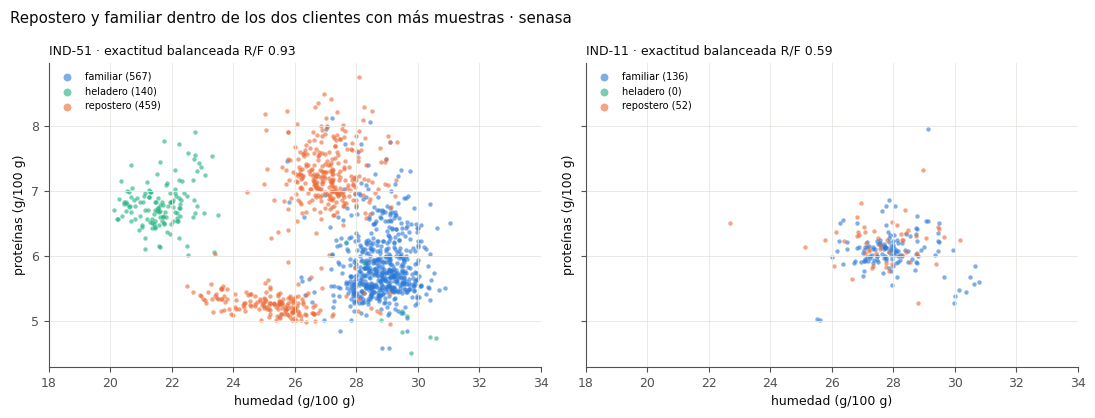

In [8]:
cr = S.crudo.set_index("Identificador")
texto = d["Identificador"].map(cr[["Descripción", "desc_producto", "desc_atributos"]].astype("string").fillna("").agg(" ".join, axis=1)).fillna("").str.upper()
palabras = {"almidón": "ALMID", "agar": r"\bAGAR", "espesante": "ESPES", "gelificante": "GELIF", "carragenina": "CARRAG",
            "pectina": "PECTIN", "horneable": "HORNE", "alfajorero": "ALFAJOR", "balde / cuñete": r"BALDE|CU[NÑ]ETE"}
display(pd.DataFrame({n_: d.loc[texto.str.contains(p_, regex=True), "subtipo"].value_counts().reindex(SUBTIPOS, fill_value=0)
                      for n_, p_ in palabras.items()}).T)
print("desc_consistencia con valor en el DDL:", int(d["Identificador"].map(cr["desc_consistencia"]).notna().sum()))

print("Repostero dentro de la regla, por cliente, y separabilidad repostero / familiar:")
filas = []
for cli, q in d.groupby("cliente"):
    n_r, n_f = (q["subtipo"] == "REPOSTERO").sum(), (q["subtipo"] == "FAMILIAR").sum()
    if n_r < 5:
        continue
    f_ = {"cliente": cli, "reposteros": int(n_r), "familiares": int(n_f), "heladeros": int((q["subtipo"] == "HELADERO").sum()),
          "sin subtipo": int((q["subtipo"] == "sin subtipo").sum())}
    for s_ in ["REPOSTERO", "FAMILIAR"]:
        for c_ in ["humedad", "proteinas"]:
            f_[f"{c_} mediana {s_.lower()}"] = round(q.loc[q["subtipo"] == s_, c_].median(), 2) if (q["subtipo"] == s_).any() else np.nan
    f_["% repostero en la regla"] = round(100 * (regla[q.index] & (q["subtipo"] == "REPOSTERO")).sum() / n_r, 0)
    if n_r >= 15 and n_f >= 15:
        qq = q[q["subtipo"].isin(["REPOSTERO", "FAMILIAR"])]
        f_["exactitud balanceada R/F"] = round(cross_val_score(MODELOS["regresión logística"](), qq[COLUMNAS], (qq["subtipo"] == "REPOSTERO").astype(int),
                                                               cv=CV_REP, scoring="balanced_accuracy").mean(), 3)
    filas.append(f_)
por_cliente = pd.DataFrame(filas).set_index("cliente").sort_values("reposteros", ascending=False); display(por_cliente)
RES[v]["por_cliente"] = por_cliente

# el repostero tiene dos modos (se ve en la dispersión): ¿en qué componentes cae cada cliente?
rep = d[d["subtipo"] == "REPOSTERO"]
print("Reposteros: componente de la mezcla actual × cliente (clientes con al menos 5 reposteros), con mediana por componente:")
tc = pd.crosstab(rep["componente"], rep["cliente"])
display(tc[[c_ for c_ in por_cliente.index if c_ in tc]].join(rep.groupby("componente")[COLUMNAS].median().round(2)))
es_alf = texto.str.contains("ALFAJOR")
print("Alfajorero, por componente:", d.loc[es_alf, "componente"].value_counts().to_dict())

# sin el cliente más grande, ¿se sigue separando?
grande = por_cliente.index[0]
resto = d[(d["cliente"] != grande)]
t_, _, _ = supervisado(resto, "REPOSTERO", ["FAMILIAR"])
print(f"Repostero contra familiar SIN {grande}:"); display(t_)
RES[v]["sin_grande"] = (grande, t_)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
top = por_cliente[por_cliente["exactitud balanceada R/F"].notna()].index[:2] if "exactitud balanceada R/F" in por_cliente else []
for ax, cli in zip(axs, top):
    q = d[d["cliente"] == cli]
    for s_ in ["FAMILIAR", "HELADERO", "REPOSTERO"]:
        qq = q[q["subtipo"] == s_]
        ax.scatter(qq["humedad"], qq["proteinas"], s=10, color=COLOR[s_], alpha=0.6, lw=0, label=f"{s_.lower()} ({len(qq)})")
    ax.set_xlim(18, 34); ax.set_xlabel("humedad (g/100 g)"); ax.set_ylabel("proteínas (g/100 g)")
    ax.set_title(f"{cli} · exactitud balanceada R/F {por_cliente.loc[cli, 'exactitud balanceada R/F']:.2f}", loc="left", fontsize=9, color=TINTA)
    ax.legend(fontsize=7, frameon=False, markerscale=1.8, loc="upper left")
fig.suptitle(f"Repostero y familiar dentro de los dos clientes con más muestras · {v}", x=0.01, ha="left", color=TINTA)
fig.tight_layout(); guardar(fig, f"por_cliente_{v}.png"); plt.show()

## 2 · Senasa + MQ
### 2.1 · Conteos por subtipo dentro del DDL
Las muestras con tag DDL de `resultados/tablas/clusters_senasa_mq.csv` (incluidos los outliers, que también llevan tag). El
subtag es el de la mezcla, recalculada con `M.subtags` (el segundo nivel anterior; el de `clusters_senasa_mq.csv` ya es otro).

In [9]:
v = "senasa_mq"
d, modelo = cargar_ddl(v, True)
print(f"{len(d)} muestras con tag DDL · mezcla con k = {modelo['k_bic']} · subtag de la mezcla recalculado")
display(pd.crosstab(d["subtipo"], d["subtag"], margins=True, margins_name="total").reindex(SUBTIPOS + ["total"]))
print("Fuente del subtipo:"); display(pd.crosstab(d["subtipo"], d["fuente_subtipo"].fillna("-")))

2226 muestras con tag DDL · mezcla con k = 6 · subtag de la mezcla recalculado


subtag,DDL,DDL_FAMILIAR,DDL_HELADERO,total
subtipo,,,,
FAMILIAR,179,610,0,789
REPOSTERO,563,74,0,637
HELADERO,35,0,140,175
sin subtipo,445,180,0,625
total,1222,864,140,2226


Fuente del subtipo:


fuente_subtipo,-,Senasa,Senasa (desc_producto),mq_tipo_muestra
subtipo,,,,
FAMILIAR,0,760,0,29
HELADERO,0,172,0,3
REPOSTERO,0,614,6,17
sin subtipo,625,0,0,0


### 2.2 · Distribución por subtipo
Medianas y percentiles 10 y 90 de los cuatro análisis. Abajo, los violines (con la mediana marcada) y la actividad de
agua (Aw), que es el único análisis extra con suficientes muestras de DDL. Los cloruros, la caseína, la ceniza ácida y la
grasa libre de MQ **no tienen ningún valor** en las muestras de DDL; los sólidos de MQ son 100 − humedad y no agregan nada.

humedad                       grasa                   proteinas                   cenizas                  
              count    10%    50%    90%  count   10%   50%   90%     count   10%   50%   90%   count   10%   50%   90%
subtipo                                                                                                                
FAMILIAR      789.0  27.47  28.75  29.94  789.0  6.05  6.73  7.58     789.0  5.37  5.85  6.55   789.0  1.19  1.36  1.56
REPOSTERO     637.0  24.53  26.64  28.27  637.0  6.00  6.81  8.36     637.0  5.19  6.63  7.74   637.0  1.16  1.50  1.76
HELADERO      175.0  20.67  21.86  25.48  175.0  4.83  6.93  7.36     175.0  6.15  6.76  7.41   175.0  2.03  2.58  2.82
sin subtipo   625.0  27.29  28.80  30.54  625.0  6.17  7.19  8.91     625.0  5.70  7.20  8.58   625.0  1.28  1.69  2.01

Otros análisis de Senasa (n con valor y mediana):


aw        carbohidratos        lactosa        sodio        
            count median         count median   count median count  median
subtipo                                                                   
FAMILIAR       89  0.836            17  55.95      18  5.995    13  155.10
REPOSTERO     220  0.804            25  60.12      21  4.940    11  163.65
HELADERO        2  0.722             6  60.32       1  9.140     5  383.60
sin subtipo    10  0.840            80  51.15       6  8.010    14  148.50

Análisis de MQ con valor en el DDL: {'mq_cloruro_nacl_g100g': 0, 'mq_cloruro_mg100g': 0, 'mq_solidos': 740, 'mq_caseina': 0, 'mq_ceniza_acida': 0, 'mq_grasa_libre': 0}


,Identificador,subtipo,subtag,componente,humedad,grasa,proteinas,cenizas
1533,MQ-34408-01,REPOSTERO,DDL,1,26.56,7.31,7.33,1.63
1545,MQ-34696-01,HELADERO,DDL_HELADERO,5,21.26,7.33,6.91,2.90
1584,MQ-35246-01,FAMILIAR,DDL_FAMILIAR,3,27.97,6.97,5.69,1.29


PNG: resultados\prueba_ddl_repostero\violines_senasa_mq.png


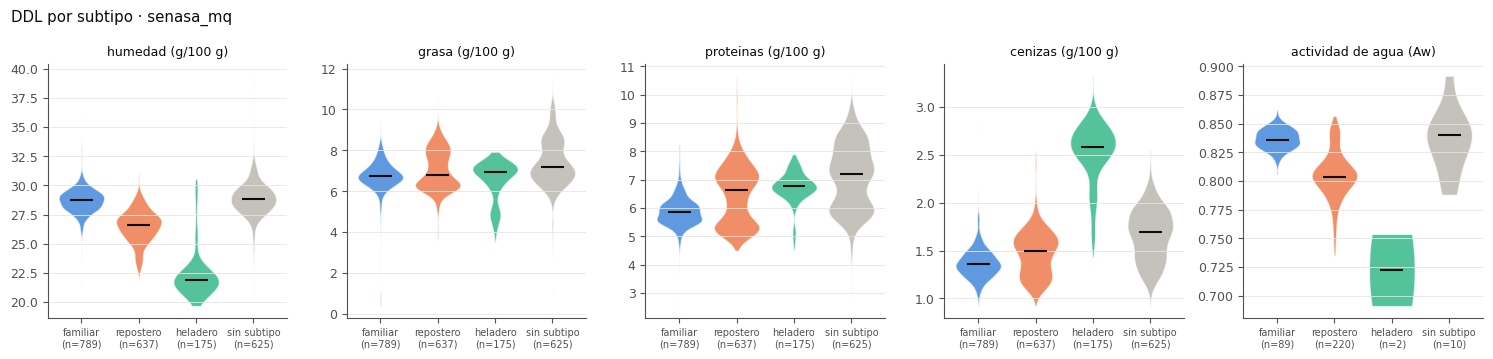

PNG: resultados\prueba_ddl_repostero\dispersion_senasa_mq.png


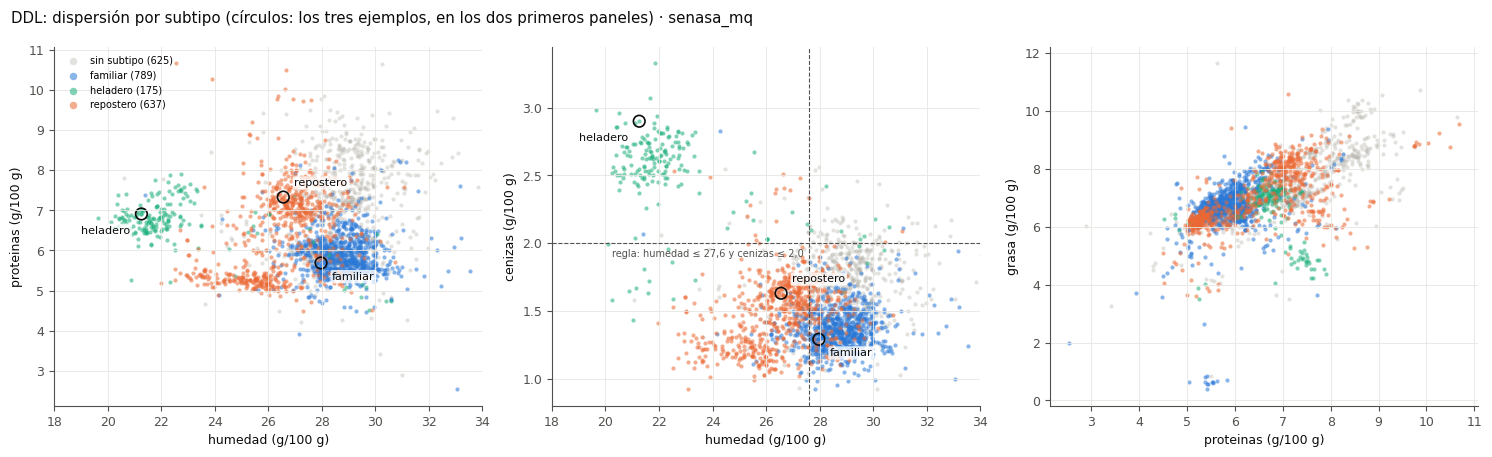

In [10]:
resumen = d.groupby("subtipo")[COLUMNAS].describe(percentiles=[.1, .5, .9]).loc[SUBTIPOS]
display(pd.concat({c_: resumen[c_][["count", "10%", "50%", "90%"]] for c_ in COLUMNAS}, axis=1).round(2))
otros = d.groupby("subtipo")[list(OTROS)].agg(["count", "median"]).reindex(SUBTIPOS).round(3)
print("Otros análisis de Senasa (n con valor y mediana):"); display(otros)
print("Análisis de MQ con valor en el DDL:", {k_: int(d[k_].notna().sum()) for k_ in d.columns if k_.startswith("mq_")})
display(d[d["Identificador"].isin(EJEMPLOS)][["Identificador", "subtipo", "subtag", "componente"] + COLUMNAS])

fig, axs = plt.subplots(1, 5, figsize=(15, 3.6))
for ax, var in zip(axs, COLUMNAS + ["aw"]):
    grupos = [d.loc[d["subtipo"] == s_, var].dropna().to_numpy() for s_ in SUBTIPOS]
    pos = [i for i, g_ in enumerate(grupos) if len(g_) > 1]
    partes = ax.violinplot([grupos[i] for i in pos], positions=pos, showmedians=True, showextrema=False, widths=0.8)
    for cuerpo, i in zip(partes["bodies"], pos):
        cuerpo.set_facecolor(COLOR[SUBTIPOS[i]]); cuerpo.set_edgecolor("white"); cuerpo.set_alpha(0.75)
    partes["cmedians"].set_color(TINTA); partes["cmedians"].set_linewidth(1.5)
    ax.set_xticks(range(len(SUBTIPOS))); ax.set_xticklabels([f"{s_.lower()}\n(n={len(g_)})" for s_, g_ in zip(SUBTIPOS, grupos)], fontsize=7)
    ax.set_title({"aw": "actividad de agua (Aw)"}.get(var, f"{var} (g/100 g)"), fontsize=9, color=TINTA); ax.grid(axis="x", visible=False)
fig.suptitle(f"DDL por subtipo · {v}", x=0.01, ha="left", color=TINTA)
fig.tight_layout(); guardar(fig, f"violines_{v}.png"); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (x_, y_) in zip(axs, [("humedad", "proteinas"), ("humedad", "cenizas"), ("proteinas", "grasa")]):
    for s_ in ["sin subtipo", "FAMILIAR", "HELADERO", "REPOSTERO"]:
        q = d[d["subtipo"] == s_]
        ax.scatter(q[x_], q[y_], s=9, color=COLOR[s_], alpha=0.55 if s_ != "sin subtipo" else 0.35, lw=0, label=f"{s_.lower()} ({len(q)})")
    for cod, rot in EJEMPLOS.items():
        q = d[d["Identificador"] == cod]
        if len(q) and x_ == "humedad":
            ax.scatter(q[x_], q[y_], s=70, facecolors="none", edgecolors=TINTA, lw=1.2)
            ax.annotate(rot, (q[x_].iloc[0], q[y_].iloc[0]), xytext={"repostero": (8, 8), "familiar": (8, -12), "heladero": (-8, -14)}[rot],
                        textcoords="offset points", fontsize=8, color=TINTA, ha="left" if rot != "heladero" else "right",
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
    if x_ == "humedad":
        ax.set_xlim(18, 34)
    ax.set_xlabel(f"{x_} (g/100 g)"); ax.set_ylabel(f"{y_} (g/100 g)")
    if (x_, y_) == ("humedad", "cenizas"):
        ax.axvline(REGLA["humedad_max"], color=TINTA2, lw=0.8, ls="--"); ax.axhline(REGLA["cenizas_max"], color=TINTA2, lw=0.8, ls="--")
        ax.text(REGLA["humedad_max"] - 0.2, REGLA["cenizas_max"] - 0.04, "regla: humedad ≤ 27,6 y cenizas ≤ 2,0", ha="right", va="top", fontsize=7, color=TINTA2)
axs[0].legend(fontsize=7, markerscale=1.8, frameon=False, loc="upper left")
fig.suptitle(f"DDL: dispersión por subtipo (círculos: los tres ejemplos, en los dos primeros paneles) · {v}", x=0.01, ha="left", color=TINTA)
fig.tight_layout(); guardar(fig, f"dispersion_{v}.png"); plt.show()

### 2.3 · Diagnóstico supervisado
LDA y regresión logística (con peso de clase balanceado) sobre las cuatro columnas estandarizadas. Validación cruzada
estratificada de 5 pliegues para la matriz de confusión, y 5 pliegues × 10 repeticiones para la media y el desvío de la
**exactitud balanceada** (0,5 = azar). Tres preguntas: repostero contra familiar, repostero contra el resto (familiar +
heladero) y, como referencia de algo que sí se separa, heladero contra el resto. Los coeficientes están en unidades de
desvío: positivo = empuja hacia el primer subtipo.

In [11]:
sup = {}
for pos_, negs_ in [("REPOSTERO", ["FAMILIAR"]), ("REPOSTERO", ["FAMILIAR", "HELADERO"]), ("HELADERO", ["FAMILIAR", "REPOSTERO"])]:
    nombre = f"{pos_.lower()} contra {' + '.join(n_.lower() for n_ in negs_)}"
    tabla, mats, coefs = supervisado(d, pos_, negs_); sup[nombre] = tabla
    print(nombre); display(tabla)
    for k_, m_ in mats.items():
        print(f"  matriz de confusión ({k_}):"); display(m_)
    print("  coeficientes:"); display(coefs.T)

repostero contra familiar


,n,n repostero,exactitud balanceada (5 pliegues),media 5×10,desvío 5×10
modelo,,,,,
LDA,1426,637,0.869,0.870,0.015
regresión logística,1426,637,0.865,0.866,0.016


  matriz de confusión (LDA):


,predicho: otro,predicho: REPOSTERO
real: otro,711,78
real: REPOSTERO,104,533


  matriz de confusión (regresión logística):


,predicho: otro,predicho: REPOSTERO
real: otro,683,106
real: REPOSTERO,86,551


... (14 outputs left out)

  matriz de confusión (regresión logística):


,predicho: otro,predicho: HELADERO
real: otro,1415,11
real: HELADERO,2,173


  coeficientes:


,humedad,grasa,proteinas,cenizas
LDA,-0.54,-0.11,-1.00,2.49
regresión logística,-1.86,-0.07,-2.19,5.05


### 2.4 · ¿En qué componentes de la mezcla actual cae el repostero?
Componente × subtipo de la mezcla (la que guardaba el joblib antes del segundo nivel por familia). El subtag sale de `proponer_subtag`: un componente lo
lleva si su subtipo mayoritario tiene pureza de al menos 60 % y cobertura de al menos 50 %, con suficientes muestras de
subtipo conocido.

subtipo,FAMILIAR,REPOSTERO,HELADERO,sin subtipo,total
componente,,,,,
0,61,83,35,51,230
1,103,293,0,166,562
2,5,163,0,4,172
3,610,74,0,180,864
4,10,24,0,224,258
5,0,0,140,0,140
total,789,637,175,625,2226


,subtag,muestras,humedad,grasa,proteinas,cenizas,con subtipo,subtipo mayoritario,% pureza,% cobertura
subgrupo,,,,,,,,,,
0,DDL,230,26.99,5.78,5.84,1.57,179,REPOSTERO,46.0,13.0
1,DDL,562,27.85,7.49,7.14,1.63,396,REPOSTERO,74.0,46.0
2,DDL,172,25.26,6.22,5.25,1.20,168,REPOSTERO,97.0,26.0
3,DDL_FAMILIAR,864,28.55,6.68,5.82,1.34,684,FAMILIAR,89.0,77.0
4,DDL,258,29.41,8.53,8.33,1.94,34,REPOSTERO,71.0,4.0
5,DDL_HELADERO,140,21.74,6.58,6.90,2.65,140,HELADERO,100.0,80.0


Componentes con mayoría de repostero: ['0', '1', '2', '4']
Si se fusionan esos componentes en un DDL_REPOSTERO: {'elegidas': 1222, 'con subtipo': 777, 'sin subtipo': 445, 'reposteros': 563, '% pureza': 72.5, '% cobertura': np.float64(88.4)}
PNG: resultados\prueba_ddl_repostero\componentes_senasa_mq.png


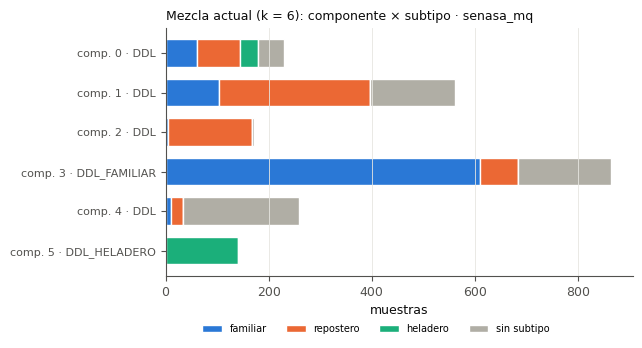

In [12]:
display(pd.crosstab(d["componente"], d["subtipo"], margins=True, margins_name="total")[SUBTIPOS + ["total"]])
display(modelo["descripcion"])
may_rep = [g_ for g_, f_ in modelo["descripcion"].iterrows() if f_["subtipo mayoritario"] == "REPOSTERO"]
print("Componentes con mayoría de repostero:", may_rep)
union_actual = pureza_cobertura(d["componente"].astype(str).isin(may_rep), d["subtipo"])
print("Si se fusionan esos componentes en un DDL_REPOSTERO:", union_actual)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
t_ = pd.crosstab(d["componente"], d["subtipo"])[SUBTIPOS]
izq = np.zeros(len(t_))
for s_ in SUBTIPOS:
    ax.barh(t_.index.astype(str), t_[s_], left=izq, color=COLOR[s_], edgecolor="white", lw=1, label=s_.lower(), height=0.7)
    izq += t_[s_].to_numpy()
sub_ = modelo["descripcion"]["subtag"]
ax.set_yticks(range(len(t_))); ax.set_yticklabels([f"comp. {g_} · {sub_.get(str(g_), '')}" for g_ in t_.index], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("muestras"); ax.grid(axis="y", visible=False)
ax.legend(fontsize=7, frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.45, -0.16))
ax.set_title(f"Mezcla actual (k = {modelo['k_bic']}): componente × subtipo · {v}", loc="left", fontsize=9, color=TINTA)
fig.tight_layout(); guardar(fig, f"componentes_{v}.png"); plt.show()

### 2.5 · La mezcla con un rango de k más amplio (1 a 12) y covarianza full / diag
Misma escala que la actual (dentro del tag) y `n_init = 3`. Para cada k: BIC, el componente con más pureza de repostero
(de al menos 20 muestras) y la **fusión** de todos los componentes con mayoría de repostero entre las de subtipo
conocido. Con covarianza full se siguen probando k hasta 20, para ver si el BIC llega a un mínimo o sigue en meseta.

BIC  mejor comp.: muestras  mejor comp.: % pureza  mejor comp.: % cobertura  fusión: componentes  fusión: % pureza  fusión: % cobertura
covarianza k                                                                                                                                            
full       1   22244                   2226                   39.8                     100.0                    0               NaN                  0.0
           2   18549                   1859                   42.8                      86.8                    0               NaN                  0.0
           3   17737                   1064                   64.7                      63.0                    1              64.7                 63.0
           4   17641                    229                   85.1                      29.7                    2              70.4                 90.7
           5   16883                    250                   75.0                       3.8                    3              64.3                 60.1
           6   16427                    172                   97.0                      25.6                    4              72.5                 88.4
           7   16446                    173                   97.0                      25.6                    5              71.2                 89.3
           8   16248                    166                   98.8                      25.1                    4              77.9                 88.2
           9   16366                    165                   98.8                      25.3                    5              81.0                 87.8
           10  16251                    168                   98.2                      25.3                    5              80.2                 84.6
           11  16276                    165                   98.2                      25.1                    6              82.9                 85.1
           12  16310                    169                   97.6                      25.3                    6              80.4                 84.6
diag       1   25330                   2226                   39.8                     100.0                    0               NaN                  0.0
           2   21577                   1134                   53.2                      58.1                    1              53.2                 58.1
           3   20441                    886                   72.2                      52.9                    1              72.2                 52.9
           4   19068                    302                   76.8                      33.3                    2              71.6                 89.2
           5   18317                    343                   73.1                      35.5                    3              71.4                 90.4
           6   17436                    224                   81.9                      27.8                    3              75.4                 81.8
           7   17237                    334                   86.4                      22.0                    4              74.8                 81.6
           8   16946                    335                   86.4                      22.0                    4              74.8                 81.5
           9   16991                    179                   97.7                      26.8                    5              84.4                 79.6
           10  16915                    177                   98.3                      26.7                    6              77.7                 84.8
           11  16719                    179                   97.1                      26.7                    6              82.5                 84.1
           12  16770                    110                  100.0                      17.0                    5              80.3                 74.9

full: BIC mínimo en k = 8 (de 1–20 probados); k con BIC a menos de 100 del mínimo: [8, 10, 11, 12, 13, 14, 15]
diag: BIC mínimo en k = 11 (de 1–12 probados); k con BIC a menos de 100 del mínimo: [11, 12]
PNG: resultados\prueba_ddl_repostero\bic_senasa_mq.png


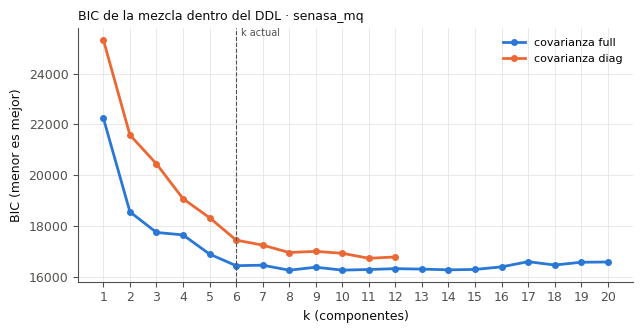

In [13]:
Z = modelo["escalador"].transform(d[COLUMNAS].to_numpy())
filas, bic = [], {}
for cov in ["full", "diag"]:
    for k_ in (range(1, 21) if cov == "full" else KS):
        g_ = GaussianMixture(n_components=k_, covariance_type=cov, n_init=3, random_state=SEMILLA).fit(Z)
        bic[(cov, k_)] = g_.bic(Z)
        if k_ not in KS:
            continue
        e_ = g_.predict(Z); t_ = pd.crosstab(e_, d["subtipo"]).reindex(columns=SUBTIPOS, fill_value=0)
        conoc = t_[["FAMILIAR", "REPOSTERO", "HELADERO"]].sum(axis=1)
        pur = (t_["REPOSTERO"] / conoc.replace(0, np.nan)).where(t_.sum(axis=1) >= 20)
        mejor = pur.idxmax() if pur.notna().any() else None
        mayoria = [i for i in t_.index if conoc[i] > 0 and t_.loc[i, "REPOSTERO"] == t_.loc[i, ["FAMILIAR", "REPOSTERO", "HELADERO"]].max()]
        u_ = pureza_cobertura(np.isin(e_, mayoria), d["subtipo"])
        filas.append({"covarianza": cov, "k": k_, "BIC": round(bic[(cov, k_)]),
                      "mejor comp.: muestras": int(t_.loc[mejor].sum()) if mejor is not None else 0,
                      "mejor comp.: % pureza": round(100 * pur[mejor], 1) if mejor is not None else np.nan,
                      "mejor comp.: % cobertura": round(100 * t_.loc[mejor, "REPOSTERO"] / t_["REPOSTERO"].sum(), 1) if mejor is not None else np.nan,
                      "fusión: componentes": len(mayoria), "fusión: % pureza": u_["% pureza"], "fusión: % cobertura": u_["% cobertura"]})
barrido = pd.DataFrame(filas).set_index(["covarianza", "k"]); display(barrido)
for cov in ["full", "diag"]:
    b_ = {k_: bic[(cov, k_)] for (c_, k_) in bic if c_ == cov}
    kmin = min(b_, key=b_.get)
    print(f"{cov}: BIC mínimo en k = {kmin} (de {min(b_)}–{max(b_)} probados); "
          f"k con BIC a menos de 100 del mínimo: {[k_ for k_ in b_ if b_[k_] - b_[kmin] < 100]}")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for cov, col_ in [("full", "#2a78d6"), ("diag", "#eb6834")]:
    ks_ = sorted(k_ for (c_, k_) in bic if c_ == cov)
    ax.plot(ks_, [bic[(cov, k_)] for k_ in ks_], marker="o", ms=4, lw=2, color=col_, label=f"covarianza {cov}")
ax.axvline(modelo["k_bic"], color=TINTA2, lw=0.8, ls="--"); ax.text(modelo["k_bic"] + 0.2, ax.get_ylim()[1], "k actual", va="top", fontsize=7, color=TINTA2)
ax.set_xlabel("k (componentes)"); ax.set_ylabel("BIC (menor es mejor)"); ax.legend(frameon=False, fontsize=8)
ax.set_xticks(range(1, 21))
ax.set_title(f"BIC de la mezcla dentro del DDL · {v}", loc="left", fontsize=9, color=TINTA)
fig.tight_layout(); guardar(fig, f"bic_{v}.png"); plt.show()

### 2.6 · Una regla simple
Un árbol de decisión de profundidad 1 a 3 (peso de clase balanceado, hojas de al menos 30 muestras), entrenado solo con
las muestras de subtipo conocido, propone los cortes; su exactitud balanceada se mide con validación cruzada. Después se
evalúa la regla fija redondeada **humedad ≤ {REGLA['humedad_max']} y cenizas ≤ {REGLA['cenizas_max']}** (la misma en
las dos versiones) sobre todo el DDL, y la regla aplicada después del heladero (solo a lo que la mezcla no manda a
DDL_HELADERO).

In [14]:
con = d[d["subtipo"] != "sin subtipo"]; y_ = (con["subtipo"] == "REPOSTERO").astype(int)
for prof in [1, 2, 3]:
    arbol = lambda: DecisionTreeClassifier(max_depth=prof, min_samples_leaf=30, class_weight="balanced", random_state=SEMILLA)
    ba = cross_val_score(arbol(), con[COLUMNAS], y_, cv=CV_REP, scoring="balanced_accuracy")
    print(f"árbol de profundidad {prof}: exactitud balanceada {ba.mean():.3f} ± {ba.std():.3f}")
    if prof == 2:
        print(export_text(arbol().fit(con[COLUMNAS], y_), feature_names=COLUMNAS, decimals=2))
regla = (d["humedad"] <= REGLA["humedad_max"]) & (d["cenizas"] <= REGLA["cenizas_max"])
reglas = {"regla: humedad ≤ 27,6 y cenizas ≤ 2,0": regla,
          "regla, fuera de DDL_HELADERO": regla & (d["subtag"] != "DDL_HELADERO"),
          "regla + (humedad ≤ 29 y proteínas > 6,8)": regla | ((d["humedad"] <= 29) & (d["proteinas"] > 6.8) & (d["cenizas"] <= REGLA["cenizas_max"])),
          "fusión de componentes de la mezcla actual": d["componente"].astype(str).isin(may_rep)}
t_reglas = pd.DataFrame({n_: pureza_cobertura(r_, d["subtipo"]) for n_, r_ in reglas.items()}).T
display(t_reglas)
print("Qué subtipo queda adentro de la regla:"); display(pd.crosstab(regla.map({True: "dentro", False: "fuera"}), d["subtipo"])[SUBTIPOS])

# esquema completo propuesto: DDL_HELADERO de la mezcla; después la regla → DDL_REPOSTERO; después DDL_FAMILIAR de la mezcla
propuesto = np.where(d["subtag"] == "DDL_HELADERO", "DDL_HELADERO", np.where(regla, "DDL_REPOSTERO", d["subtag"]))
print("Esquema propuesto (heladero → regla de repostero → familiar) contra el subtipo:")
display(pd.crosstab(pd.Series(propuesto, name="subtag propuesto"), d["subtipo"], margins=True, margins_name="total")[SUBTIPOS + ["total"]])
esquema = pd.DataFrame({st_: pureza_cobertura(propuesto == f"DDL_{st_}", d["subtipo"], st_) for st_ in ["FAMILIAR", "REPOSTERO", "HELADERO"]}).T
esquema = esquema[["elegidas", "con subtipo", "sin subtipo", "% pureza", "% cobertura"]]
print("Pureza y cobertura de cada subtag con el esquema propuesto (antes: familiar 90 / 78, heladero 100 / 80):"); display(esquema)
anio = pd.to_datetime(d["Identificador"].map(S.crudo.set_index("Identificador")["Fecha de Recepción"]), errors="coerce", dayfirst=True).dt.year
print("La regla por año de recepción (pureza / cobertura del repostero):")
display(pd.DataFrame({int(a_): pureza_cobertura(regla[anio == a_], d.loc[anio == a_, "subtipo"].reset_index(drop=True))
                      for a_ in sorted(anio.dropna().unique())}).T[["con subtipo", "% pureza", "% cobertura"]])
RES[v] = dict(n=len(d), esquema=esquema, conteos=d["subtipo"].value_counts().to_dict(), medianas=d.groupby("subtipo")[COLUMNAS].median().round(2),
              sup=sup, regla=t_reglas, barrido=barrido, union_actual=union_actual, d=d)

árbol de profundidad 1: exactitud balanceada 0.763 ± 0.022
árbol de profundidad 2: exactitud balanceada 0.862 ± 0.017
|--- humedad <= 27.68
|   |--- humedad <= 22.90
|   |   |--- class: 0
|   |--- humedad >  22.90
|   |   |--- class: 1
|--- humedad >  27.68
|   |--- proteinas <= 6.78
|   |   |--- class: 0
|   |--- proteinas >  6.78
|   |   |--- class: 1



árbol de profundidad 3: exactitud balanceada 0.859 ± 0.017


,elegidas,con subtipo,sin subtipo,reposteros,% pureza,% cobertura
"regla: humedad ≤ 27,6 y cenizas ≤ 2,0",683.0,601.0,82.0,495.0,82.4,77.7
"regla, fuera de DDL_HELADERO",683.0,601.0,82.0,495.0,82.4,77.7
"regla + (humedad ≤ 29 y proteínas > 6,8)",873.0,680.0,193.0,556.0,81.8,87.3
fusión de componentes de la mezcla actual,1222.0,777.0,445.0,563.0,72.5,88.4


Qué subtipo queda adentro de la regla:


subtipo,FAMILIAR,REPOSTERO,HELADERO,sin subtipo
row_0,,,,
dentro,94,495,12,82
fuera,695,142,163,543


Esquema propuesto (heladero → regla de repostero → familiar) contra el subtipo:


subtipo,FAMILIAR,REPOSTERO,HELADERO,sin subtipo,total
subtag propuesto,,,,,
DDL,153,102,23,394,672
DDL_FAMILIAR,542,40,0,149,731
DDL_HELADERO,0,0,140,0,140
DDL_REPOSTERO,94,495,12,82,683
total,789,637,175,625,2226


Pureza y cobertura de cada subtag con el esquema propuesto (antes: familiar 90 / 78, heladero 100 / 80):


,elegidas,con subtipo,sin subtipo,% pureza,% cobertura
FAMILIAR,731.0,582.0,149.0,93.1,68.7
REPOSTERO,683.0,601.0,82.0,82.4,77.7
HELADERO,140.0,140.0,0.0,100.0,80.0


La regla por año de recepción (pureza / cobertura del repostero):


,con subtipo,% pureza,% cobertura
2020,40.0,57.5,50.0
2021,38.0,73.7,49.1
2022,75.0,74.7,78.9
2023,131.0,90.1,90.1
2024,107.0,76.6,91.1
2025,114.0,86.0,79.0
2026,89.0,94.4,81.6


### 2.7 · Causa probable: ¿otra cosa que no sea la composición, o la etiqueta?
Tres miradas. (a) La **actividad de agua** y los carbohidratos, que no entran en el agrupamiento. (b) El **texto** de
`Descripción`, `desc_producto` y `desc_atributos`: ¿se menciona algún espesante o ingrediente (almidón, agar, gelificante,
carragenina, pectina)? ¿`desc_consistencia` dice algo? (c) La separabilidad **por cliente** (solo el código IND-nn):
regresión logística repostero contra familiar dentro de cada cliente con al menos 15 de cada uno, y las medianas.

subtipo,FAMILIAR,REPOSTERO,HELADERO,sin subtipo
almidón,0,0,0,0
agar,0,0,0,0
espesante,0,0,0,0
gelificante,0,0,0,0
carragenina,0,0,0,0
pectina,0,0,0,0
horneable,0,0,0,0
alfajorero,0,27,0,0
balde / cuñete,0,14,1,0


desc_consistencia con valor en el DDL: 0
Repostero dentro de la regla, por cliente, y separabilidad repostero / familiar:


,reposteros,familiares,heladeros,sin subtipo,humedad mediana repostero,proteinas mediana repostero,humedad mediana familiar,proteinas mediana familiar,% repostero en la regla,exactitud balanceada R/F
cliente,,,,,,,,,,
IND-51,459,576,158,12,26.60,6.91,28.82,5.74,84.0,0.930
IND-11,52,136,0,61,27.78,6.25,27.88,6.08,48.0,0.588
IND-107,29,4,0,12,26.42,5.70,28.36,4.48,79.0,NaN
IND-71,17,3,2,2,24.11,5.77,32.44,5.49,88.0,NaN
IND-38,15,4,0,326,26.34,9.74,30.88,8.21,13.0,NaN
IND-52,12,16,2,5,26.10,5.68,27.80,5.06,100.0,NaN
IND-67,9,0,0,89,25.35,6.81,NaN,NaN,100.0,NaN
IND-81,6,0,5,0,26.89,8.02,NaN,NaN,67.0,NaN


Reposteros: componente de la mezcla actual × cliente (clientes con al menos 5 reposteros), con mediana por componente:


,IND-51,IND-11,IND-107,IND-71,IND-38,IND-52,IND-67,IND-81,humedad,grasa,proteinas,cenizas
componente,,,,,,,,,,,,
0,15,2,25,17,0,7,4,0,25.70,6.33,5.94,1.52
1,267,7,0,0,1,1,5,3,27.05,7.83,7.19,1.61
2,159,0,1,0,0,0,0,0,25.40,6.24,5.26,1.20
3,14,43,3,0,0,3,0,0,27.80,6.55,6.02,1.35
4,4,0,0,0,14,1,0,3,26.79,8.82,8.80,2.12


Alfajorero, por componente: {0: 24, 3: 2, 2: 1}


Repostero contra familiar SIN IND-51:


,n,n repostero,exactitud balanceada (5 pliegues),media 5×10,desvío 5×10
modelo,,,,,
LDA,391,178,0.739,0.731,0.039
regresión logística,391,178,0.729,0.724,0.050


PNG: resultados\prueba_ddl_repostero\por_cliente_senasa_mq.png


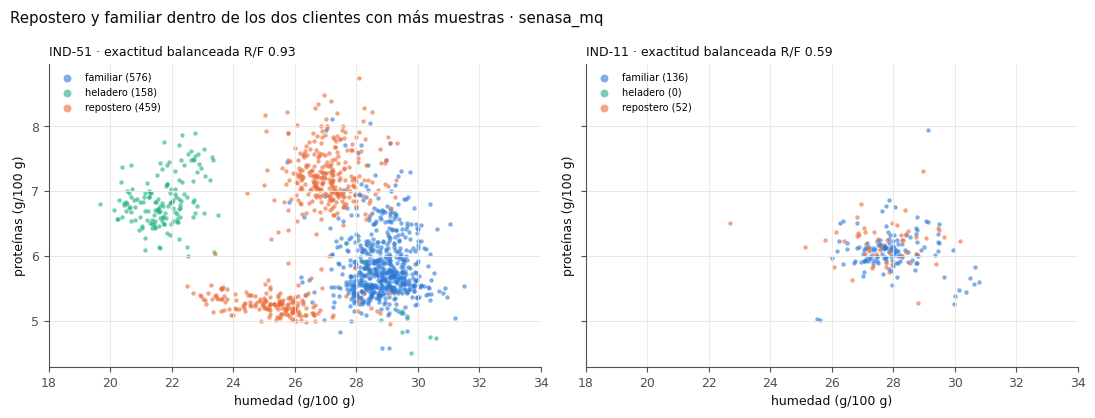

In [15]:
cr = S.crudo.set_index("Identificador")
texto = d["Identificador"].map(cr[["Descripción", "desc_producto", "desc_atributos"]].astype("string").fillna("").agg(" ".join, axis=1)).fillna("").str.upper()
palabras = {"almidón": "ALMID", "agar": r"\bAGAR", "espesante": "ESPES", "gelificante": "GELIF", "carragenina": "CARRAG",
            "pectina": "PECTIN", "horneable": "HORNE", "alfajorero": "ALFAJOR", "balde / cuñete": r"BALDE|CU[NÑ]ETE"}
display(pd.DataFrame({n_: d.loc[texto.str.contains(p_, regex=True), "subtipo"].value_counts().reindex(SUBTIPOS, fill_value=0)
                      for n_, p_ in palabras.items()}).T)
print("desc_consistencia con valor en el DDL:", int(d["Identificador"].map(cr["desc_consistencia"]).notna().sum()))

print("Repostero dentro de la regla, por cliente, y separabilidad repostero / familiar:")
filas = []
for cli, q in d.groupby("cliente"):
    n_r, n_f = (q["subtipo"] == "REPOSTERO").sum(), (q["subtipo"] == "FAMILIAR").sum()
    if n_r < 5:
        continue
    f_ = {"cliente": cli, "reposteros": int(n_r), "familiares": int(n_f), "heladeros": int((q["subtipo"] == "HELADERO").sum()),
          "sin subtipo": int((q["subtipo"] == "sin subtipo").sum())}
    for s_ in ["REPOSTERO", "FAMILIAR"]:
        for c_ in ["humedad", "proteinas"]:
            f_[f"{c_} mediana {s_.lower()}"] = round(q.loc[q["subtipo"] == s_, c_].median(), 2) if (q["subtipo"] == s_).any() else np.nan
    f_["% repostero en la regla"] = round(100 * (regla[q.index] & (q["subtipo"] == "REPOSTERO")).sum() / n_r, 0)
    if n_r >= 15 and n_f >= 15:
        qq = q[q["subtipo"].isin(["REPOSTERO", "FAMILIAR"])]
        f_["exactitud balanceada R/F"] = round(cross_val_score(MODELOS["regresión logística"](), qq[COLUMNAS], (qq["subtipo"] == "REPOSTERO").astype(int),
                                                               cv=CV_REP, scoring="balanced_accuracy").mean(), 3)
    filas.append(f_)
por_cliente = pd.DataFrame(filas).set_index("cliente").sort_values("reposteros", ascending=False); display(por_cliente)
RES[v]["por_cliente"] = por_cliente

# el repostero tiene dos modos (se ve en la dispersión): ¿en qué componentes cae cada cliente?
rep = d[d["subtipo"] == "REPOSTERO"]
print("Reposteros: componente de la mezcla actual × cliente (clientes con al menos 5 reposteros), con mediana por componente:")
tc = pd.crosstab(rep["componente"], rep["cliente"])
display(tc[[c_ for c_ in por_cliente.index if c_ in tc]].join(rep.groupby("componente")[COLUMNAS].median().round(2)))
es_alf = texto.str.contains("ALFAJOR")
print("Alfajorero, por componente:", d.loc[es_alf, "componente"].value_counts().to_dict())

# sin el cliente más grande, ¿se sigue separando?
grande = por_cliente.index[0]
resto = d[(d["cliente"] != grande)]
t_, _, _ = supervisado(resto, "REPOSTERO", ["FAMILIAR"])
print(f"Repostero contra familiar SIN {grande}:"); display(t_)
RES[v]["sin_grande"] = (grande, t_)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
top = por_cliente[por_cliente["exactitud balanceada R/F"].notna()].index[:2] if "exactitud balanceada R/F" in por_cliente else []
for ax, cli in zip(axs, top):
    q = d[d["cliente"] == cli]
    for s_ in ["FAMILIAR", "HELADERO", "REPOSTERO"]:
        qq = q[q["subtipo"] == s_]
        ax.scatter(qq["humedad"], qq["proteinas"], s=10, color=COLOR[s_], alpha=0.6, lw=0, label=f"{s_.lower()} ({len(qq)})")
    ax.set_xlim(18, 34); ax.set_xlabel("humedad (g/100 g)"); ax.set_ylabel("proteínas (g/100 g)")
    ax.set_title(f"{cli} · exactitud balanceada R/F {por_cliente.loc[cli, 'exactitud balanceada R/F']:.2f}", loc="left", fontsize=9, color=TINTA)
    ax.legend(fontsize=7, frameon=False, markerscale=1.8, loc="upper left")
fig.suptitle(f"Repostero y familiar dentro de los dos clientes con más muestras · {v}", x=0.01, ha="left", color=TINTA)
fig.tight_layout(); guardar(fig, f"por_cliente_{v}.png"); plt.show()

## 3 · Las dos versiones, lado a lado

In [16]:
filas = []
for v_, r_ in RES.items():
    f_ = {"versión": v_, "muestras DDL": r_["n"]} | {f"n {k_.lower()}": r_["conteos"].get(k_, 0) for k_ in SUBTIPOS}
    for n_, t_ in r_["sup"].items():
        if n_.startswith("repostero"):
            f_[f"BA {n_} (LR, 5×10)"] = t_.loc["regresión logística", "media 5×10"]
            f_[f"BA {n_} (LDA, 5×10)"] = t_.loc["LDA", "media 5×10"]
    f_["BA repostero/familiar sin el cliente mayor (LR)"] = r_["sin_grande"][1].loc["regresión logística", "media 5×10"]
    for n_ in r_["regla"].index:
        f_[f"{n_}: pureza / cobertura"] = f"{r_['regla'].loc[n_, '% pureza']} / {r_['regla'].loc[n_, '% cobertura']}"
    b_ = r_["barrido"].loc["full"]
    f_["mezcla full: k con BIC mínimo (1–12)"] = int(b_["BIC"].idxmin())
    filas.append(f_)
display(pd.DataFrame(filas).set_index("versión").T)
for v_, r_ in RES.items():
    print(v_, "medianas por subtipo:"); display(r_["medianas"])

versión,senasa,senasa_mq
muestras DDL,2116,2226
n familiar,749,789
n repostero,620,637
n heladero,152,175
n sin subtipo,595,625
"BA repostero contra familiar (LR, 5×10)",0.868,0.866
"BA repostero contra familiar (LDA, 5×10)",0.872,0.87
"BA repostero contra familiar + heladero (LR, 5×10)",0.827,0.827
"BA repostero contra familiar + heladero (LDA, 5×10)",0.819,0.82
BA repostero/familiar sin el cliente mayor (LR),0.724,0.724


senasa medianas por subtipo:


,humedad,grasa,proteinas,cenizas
subtipo,,,,
FAMILIAR,28.70,6.75,5.84,1.36
HELADERO,21.76,7.02,6.73,2.56
REPOSTERO,26.64,6.84,6.63,1.50
sin subtipo,28.81,7.21,7.16,1.70


senasa_mq medianas por subtipo:


,humedad,grasa,proteinas,cenizas
subtipo,,,,
FAMILIAR,28.75,6.73,5.85,1.36
HELADERO,21.86,6.93,6.76,2.58
REPOSTERO,26.64,6.81,6.63,1.50
sin subtipo,28.80,7.19,7.20,1.69


## 4 · Veredicto
### ¿Se puede crear DDL_REPOSTERO?

**Sí, pero no con el agrupamiento actual.** Lo que funciona es una **regla** sobre dos análisis, y la señal viene casi
toda de un solo cliente.

- **Regla propuesta**: dentro del tag DDL y fuera de DDL_HELADERO, **humedad ≤ 27,6 y cenizas ≤ 2,0 g/100 g** →
  DDL_REPOSTERO. En solo Senasa da **82,6 % de pureza y 78,9 % de cobertura** (670 muestras: 489 reposteros, 93
  familiares, 10 heladeros y 78 sin subtipo). En Senasa + MQ (MQ encolumnado, sin las MO) da 82,4 % y 77,7 %. Primero va el heladero (mezcla), después
  la regla y al final el familiar (mezcla). Con ese orden, DDL_FAMILIAR sube de 90 % a 93 % de pureza, pero su
  cobertura baja de 78 % a 69 %. DDL_HELADERO no cambia.
- Un árbol de profundidad 2 llega a cortes parecidos (exactitud balanceada 0,86 en validación cruzada): primero humedad
  ≤ 27,6, igual que la regla; del lado seco ya no corta por cenizas sino por humedad (> 22,9 es repostero, lo que deja
  afuera al heladero) y del lado húmedo por proteínas > 6,8. Los umbrales se
  eligieron **mirando la etiqueta**, así que es una regla supervisada y no un hallazgo del agrupamiento. Hay que
  presentarla así.

### Evidencia

1. **Dónde está.** El repostero queda entre el familiar y el heladero. Medianas (humedad / grasa / proteínas / cenizas):
   familiar 28,7 / 6,8 / 5,8 / 1,36; repostero 26,6 / 6,8 / 6,6 / 1,50; heladero 21,8 / 7,0 / 6,7 / 2,56. Tiene menos agua
   que el familiar y más proteína, pero sin las cenizas del heladero. Además es **bimodal**: un modo seco y magro
   (humedad ≈ 25, proteínas ≈ 5,2, cenizas ≈ 1,2) y otro con humedad ≈ 27, proteínas ≈ 7,2 y cenizas ≈ 1,6.
2. **Supervisado.** Repostero contra familiar: exactitud balanceada **0,87** (LDA y logística). Repostero contra el resto:
   **0,82 y 0,83**. Pesan la humedad (−) y las proteínas (+), y contra el resto también las cenizas (−). Como referencia, el
   heladero da 0,96 a 0,99. Se separa bastante, pero no tan limpio como el heladero.
3. **La mezcla.** El repostero se reparte en cuatro componentes con mayoría de repostero (y 68 de los 620 caen en el del
   familiar). En solo Senasa, uno es 98 % puro pero cubre solo el 26 %; otro tiene 74 % de pureza y 43 % de cobertura (con
   MQ, 97 % y 26 %, y 74 % y 46 %). Ningún componente puro llega al 50 % de cobertura, así que `proponer_subtag` lo rechaza con
   razón. Con k de 6 a 12, full o diag, el componente más puro nunca pasa de alrededor del 26 % de cobertura; con k menores
   es menos puro (83 % con k = 5). Fusionar los
   componentes con mayoría de repostero da 74 % de pureza y 89 % de cobertura, peor que la regla. **El BIC no tiene un
   mínimo real**: con full el mínimo cae en k = 8 en las dos versiones, pero queda en meseta desde k ≈ 6 (en solo Senasa, de 6 a 12
   están a menos de 100 del mínimo; con MQ, 8 y de 10 a 15) y con diag sigue bajando hasta el borde del rango (k = 12 en solo
   Senasa, k = 11 con MQ). El k = 6 no es un número que el BIC haya encontrado.

### Causa probable

- **La etiqueta depende del cliente.** El cliente mayor (IND-51) aporta 459 de los 620 reposteros, y su repostero es una
  receta propia, separable del familiar del mismo cliente (exactitud balanceada 0,93). Los dos modos y el componente
  puro son suyos. En IND-11, el repostero **tiene la misma composición** que el familiar (medianas 27,8 contra 27,9 de
  humedad; exactitud balanceada 0,59; la regla captura el 48 %). Sin IND-51, el supervisado baja a 0,72 con la logística (0,74 con LDA). La pureza de la
  regla también varía por año: 57,5 % y 73,7 % en 2020–2021, entre 74,7 % y 95,5 % después.
- **Sí hay un rasgo físico.** La actividad de agua del repostero es más baja (mediana 0,804 contra 0,836, con 220 y 89
  muestras): es más concentrado y más firme. Eso concuerda con un producto pensado por textura o consistencia. No hay
  forma de ver espesantes: ninguna descripción menciona almidón, agar, gelificante, carragenina ni pectina, y
  `desc_consistencia` está vacío en todo el DDL. Los cloruros, la caseína y la ceniza ácida de MQ no tienen ningún valor
  en el DDL.

### Dudas

- Si DDL_REPOSTERO entra, entra **como regla documentada**, no como subtag del agrupamiento. En la práctica describe el
  repostero de IND-51. Una muestra repostera de otro cliente, con fórmula de familiar, va a caer en DDL_FAMILIAR o en DDL.
- 595 muestras de DDL (625 en Senasa + MQ) no tienen subtipo, 326 de ellas de IND-38, que casi no rotula. La pureza se
  mide solo sobre las que tienen subtipo conocido.
- Alfajorero (27 muestras) cae casi todo en un componente mixto. Habría que decidir si es un repostero o un subtipo aparte.